# SQP

In [1]:
import casadi as ca
import numpy as np
import matplotlib.pyplot as plt

from solvers.sqp import sqp

# Results storage for summary
optimization_results = []


# Helper function to record results
def record_result(example_name, x_g, l_g, post_proc, x_initial, m_g=None):
    """Record optimization result for summary"""
    result = {
        "example": example_name,
        "initial_guess": x_initial.flatten(),
        "iterations": len(post_proc["step"]),
        "solution": x_g.flatten(),
        "kkt_violation": post_proc["kkt_violation"][-1],
    }
    result["equality_multiplier"] = l_g.flatten()
    if m_g is not None:
        result["inequality_multiplier"] = m_g.flatten()
    optimization_results.append(result)


def fmt(v, digits=4):
    """Format a vector with the given number of significant digits"""
    return "[" + ", ".join(f"{e:.{digits}g}" for e in v) + "]"

## SQP solver

The solver is implemented in `solvers/sqp.py` and solves
$$\min_x \; f(x) \quad \text{s.t.} \quad g(x) = 0, \quad h(x) \le 0$$
with $L = f + \lambda^\top g + \mu^\top h$. At each iteration:

- **Hessian**: $B = \nabla^2_{xx} L$ (`hessian="exact"`), or the Gauss-Newton approximation $B = \nabla R \nabla R^\top$ for a cost $f = \frac{1}{2}\|R(x)\|^2$ (`hessian="gauss-newton"`, residual passed as `R`).
- **Hessian regularization**: eigenvalue modification on the null space $Z$ of $[\nabla g \;\; \nabla h_\mathcal{A}]^\top$, where the active set $\mathcal{A}$ is estimated from the current multipliers ($\mu_i > 0$).
- **Newton direction**: solve the QP (with qpOASES)
  $$\min_{\Delta x} \; \tfrac{1}{2} \Delta x^\top B \Delta x + \nabla f^\top \Delta x \quad \text{s.t.} \quad g + \nabla g^\top \Delta x = 0 \;\; | \; \lambda^{QP}, \qquad h + \nabla h^\top \Delta x \le 0 \;\; | \; \mu^{QP}.$$
  If the QP is infeasible (incompatible linearized constraints) the solver stops with an error. The QP is convex only if $B \succeq 0$: the regularization only ensures $Z^\top B Z \succ 0$, so the QP can be nonconvex (column *QP convex* of the table).
- **Line search**: Armijo backtracking on the $\ell_1$ merit function $M_1(x) = f(x) + \sigma \left( \|g(x)\|_1 + \|\max(h(x), 0)\|_1 \right)$, with $\sigma > \|(\lambda^{QP}, \mu^{QP})\|_\infty$, updated at each iteration starting from $\sigma = 0$.
- **Step**: $x \leftarrow x + \alpha \Delta x$, $\quad \lambda \leftarrow (1 - \alpha)\lambda + \alpha \lambda^{QP}$, $\quad \mu \leftarrow (1 - \alpha)\mu + \alpha \mu^{QP}$.

The solver stops when the KKT violation $\|(\nabla_x L, g, \max(0, h))\|_\infty$ is below tol, or when the line search fails.

## Plot function

In [2]:
def plot_contour_and_kkt(post_proc, f, g, x_g, h=None):
    fig = plt.figure(figsize=(12, 10))

    # Contour plot in the (x1, x2) plane: only for problems with 2 variables
    if x_g.shape[0] == 2:
        x1 = np.linspace(-3, 3, 100)
        x2 = np.linspace(-3, 3, 100)
        X1, X2 = np.meshgrid(x1, x2)

        # Evaluate functions on mesh
        F = np.zeros_like(X1)
        G = np.zeros_like(X1)
        if h is not None:
            H = np.zeros_like(X1)
        for i in range(X1.shape[0]):
            for j in range(X1.shape[1]):
                x_val = np.array([[X1[i, j]], [X2[i, j]]])
                F[i, j] = float(f(x_val))
                G[i, j] = float(g(x_val))
                if h is not None:
                    H[i, j] = float(h(x_val))

        # x1, x2 contour of f and g=0
        ax = fig.add_subplot(221)
        ax.contour(X1, X2, F, levels=50, cmap="viridis")
        ax.contour(X1, X2, G, levels=[0], colors="red", linewidths=2)
        if h is not None:
            ax.contour(X1, X2, H, levels=[0], colors="blue", linewidths=2)
            # Plot the area where h(x) < 0
            ax.contourf(X1, X2, H, levels=[-np.inf, 0], colors="blue", alpha=0.3)

        x_hist_array = np.array(post_proc["x"])
        ax.plot(
            x_hist_array[:, 0],
            x_hist_array[:, 1],
            "k-o",
            label="Iterations",
            linewidth=2,
            markersize=4,
        )
        ax.plot(x_g[0], x_g[1], "ro", label="Optimal Point", markersize=8)
        ax.set_title("Contour of f(x) and g(x)=0")
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
        ax.legend()
        ax.set_aspect("equal", adjustable="box")
        ax.grid()

    # KKT violation plot
    ax = fig.add_subplot(222)
    ax.semilogy(post_proc["kkt_violation"], "b-o", linewidth=2, markersize=4)
    ax.set_title("KKT Violation over Iterations")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("KKT Violation")
    ax.grid()

    # alpha plot
    ax = fig.add_subplot(223)
    ax.plot(post_proc["step"], post_proc["alpha"], "m-o", linewidth=2, markersize=4)
    ax.set_title("Step Size (alpha) over Iterations")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Alpha")
    ax.grid()

    # Objective function value plot
    ax = fig.add_subplot(224)
    f_values = [float(f(x.reshape(-1, 1))) for x in post_proc["x"]]
    ax.plot(post_proc["step"], f_values[1:], "g-o", linewidth=2, markersize=4)
    ax.set_title("Objective Function over Iterations")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("f(x)")
    ax.grid()

    plt.tight_layout()
    return fig

## Test on a QP

With a convex QP the SQP method must converge in **one step**: the QP solved at the first iteration is the problem itself.

In [3]:
x = ca.SX.sym("x", 2)
Q = np.array([[2.0, 1.0], [1.0, 3.0]])
f_qp = ca.Function("f", [x], [0.5 * x.T @ Q @ x + x[0]])
g_qp = ca.Function("g", [x], [x[0] + x[1] - 1])
h_qp = ca.Function("h", [x], [x[0] - 0.2])  # active at the solution

x_qp, l_qp, m_qp, post_proc = sqp(
    f_qp, g_qp, h_qp, np.array([[5.0], [5.0]]), np.array([[0.0]]), np.array([[0.0]]), tol=1e-8
)


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size | QP convex |                               x |                   λ

qpOASES -- An Implementation of the Online Active Set Strategy.
Copyright (C) 2007-2015 by Hans Joachim Ferreau, Andreas Potschka,
Christian Kirches et al. All rights reserved.

qpOASES is distributed under the terms of the 
GNU Lesser General Public License 2.1 in the hope that it will be 
useful, but WITHOUT ANY WARRANTY; without even the implied warranty 
of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. 
See the GNU Lesser General Public License for more details.


qpOASES -- An Implementation of the Online Active Set Strategy.
Copyright (C) 2007-2015 by Hans Joachim Ferreau, Andreas Potschka,
Christian Kirches et al. All rights reserved.

qpOASES is distributed under the terms of the 
GNU Lesser General Public License 2.1 in the hope that it will be 
useful, but WITHOUT ANY WARRANTY; without even the implied warranty 
of MERCHANTABILITY or 

**Infeasibility and non-convexity.** If the linearized constraints are incompatible the QP is infeasible: `sqp` checks the status of the QP solver and stops with an error.

The Hessian regularization only ensures $Z^\top B Z \succ 0$ on the null space of the active constraints: $B$ itself can be indefinite, and the QP is then **nonconvex** (column *QP convex* of the table). Such a QP is still well posed if the reduced Hessian is positive definite on the active set, but Matlab's `quadprog` rejects nonconvex QPs unless the convexity check is disabled (`opts.ConvexCheck = 'off'`). qpOASES, used here, accepts them.

## Example 3

$$\min_x \; x^\top x + \mathbf{1}^\top x \quad \text{s.t.} \quad x^\top x = 1, \quad 0.5 - x_1^2 - x_2 \le 0$$

**Is the inequality constraint convex?** No. $h(x) = 0.5 - x_1^2 - x_2$ has Hessian $\mathrm{diag}(-2, 0) \preceq 0$: $h$ is concave, and the set $\{h \le 0\} = \{x_2 \ge 0.5 - x_1^2\}$ is not convex. For instance $(-1, -0.5)$ and $(1, -0.5)$ are feasible, but their midpoint $(0, -0.5)$ is not. The equality constraint $x^\top x = 1$ is nonconvex as well.

In [4]:
nx = 2
x = ca.SX.sym("x", nx)

_f = x.T @ x + ca.SX.ones(nx).T @ x
f = ca.Function("f", [x], [_f])

_g = x.T @ x - 1
g = ca.Function("g", [x], [_g])

_h = 0.5 - x[0] ** 2 - x[1]
h = ca.Function("h", [x], [_h])

### Initial guesses $(0, 1)$ and $(-1, -1)$


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size | QP convex |                               x |                   λ

qpOASES -- An Implementation of the Online Active Set Strategy.
Copyright (C) 2007-2015 by Hans Joachim Ferreau, Andreas Potschka,
Christian Kirches et al. All rights reserved.

qpOASES is distributed under the terms of the 
GNU Lesser General Public License 2.1 in the hope that it will be 
useful, but WITHOUT ANY WARRANTY; without even the implied warranty 
of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. 
See the GNU Lesser General Public License for more details.


qpOASES -- An Implementation of the Online Active Set Strategy.
Copyright (C) 2007-2015 by Hans Joachim Ferreau, Andreas Potschka,
Christian Kirches et al. All rights reserved.

qpOASES is distributed under the terms of the 
GNU Lesser General Public License 2.1 in the hope that it will be 
useful, but WITHOUT ANY WARRANTY; without even the implied warranty 
of MERCHANTABILITY or 

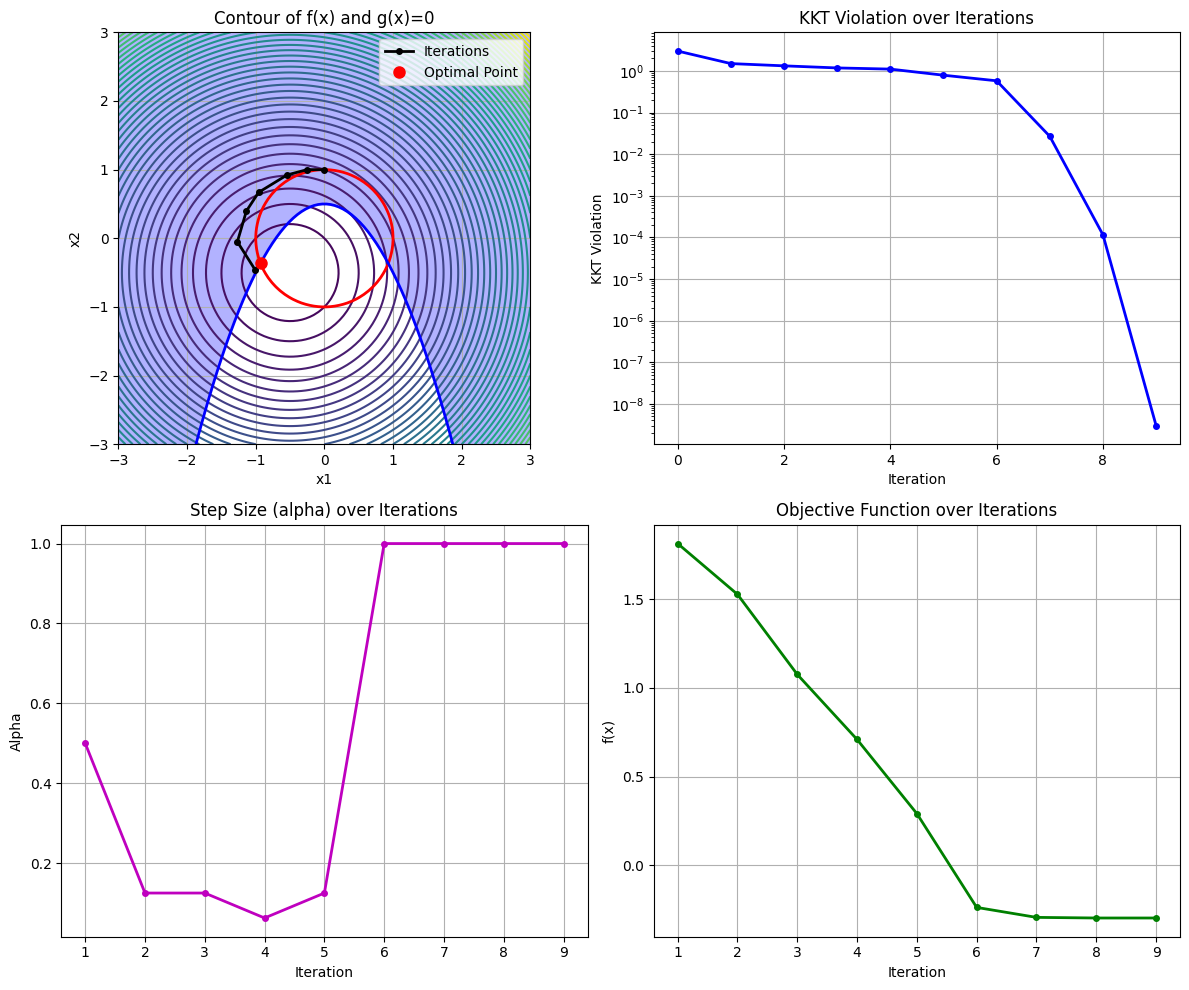

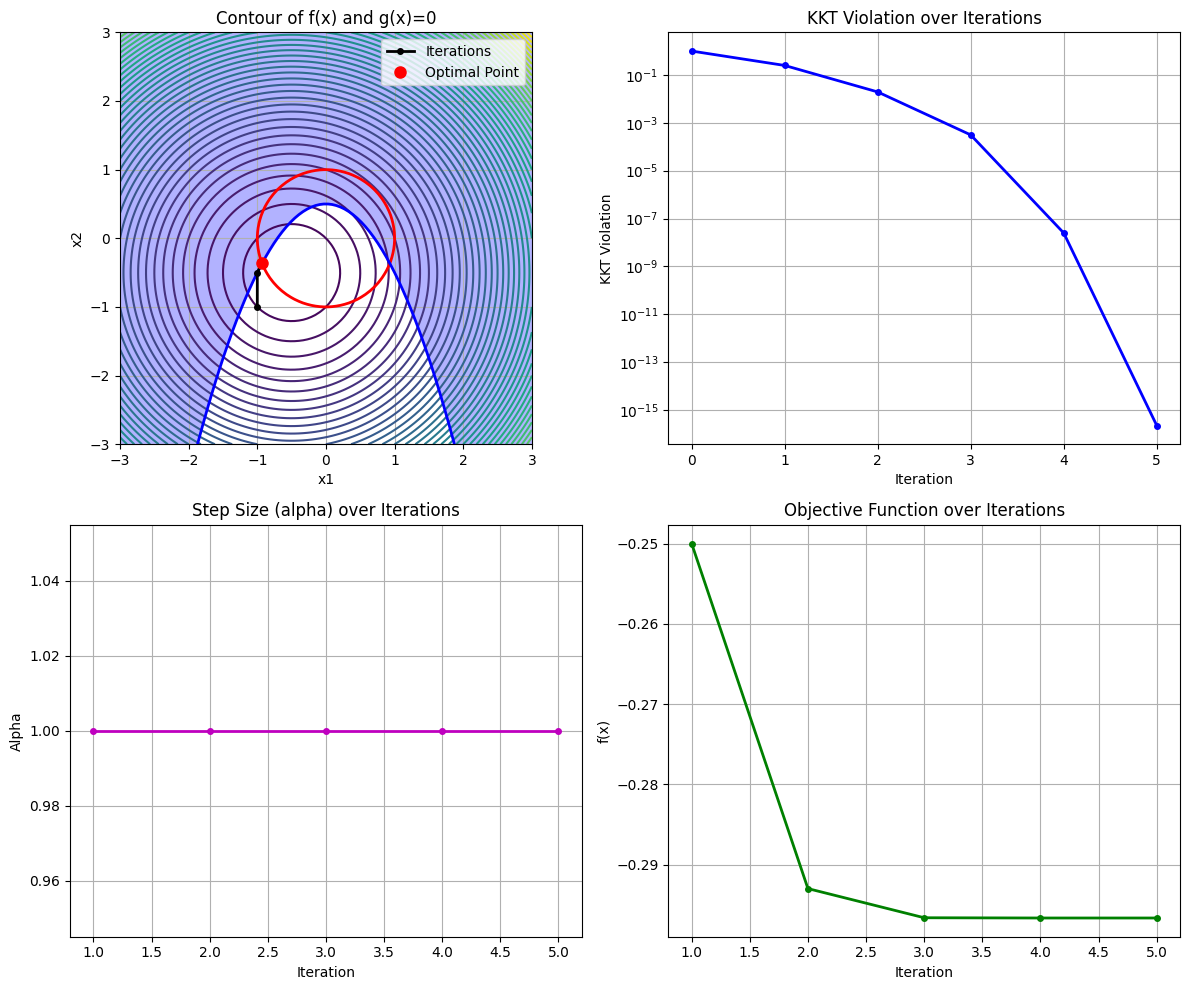

In [5]:
# 1
x_g = np.array([[0.0], [1.0]])
l_g = np.zeros_like([[0.0]])
m_g = np.zeros_like([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, m_g, post_proc = sqp(
        f, g, h, x_g, l_g, m_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-8, max_iter=400
    )
    record_result("Example 3", x_g, l_g, post_proc, x_init, m_g)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g, h)
except Exception as e:
    print("Error during optimization:", e)

# 2
x_g = np.array([[-1.0], [-1.0]])
l_g = np.zeros_like([[0.0]])
m_g = np.zeros_like([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, m_g, post_proc = sqp(
        f, g, h, x_g, l_g, m_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-8, max_iter=400
    )
    record_result("Example 3", x_g, l_g, post_proc, x_init, m_g)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g, h)
except Exception as e:
    print("Error during optimization:", e)

**Observations.** Both initial guesses converge to $x^* = (-0.9306, -0.3660)$, $f^* = -0.297$, with $\lambda^* = -0.112$ and the inequality **active**: $h(x^*) = 0$, $\mu^* = 0.350 > 0$. The solution of Example 1 (without the inequality), $-\tfrac{1}{\sqrt{2}}(1, 1)$, is now infeasible ($h = \tfrac{1}{\sqrt{2}} > 0$).

### Initial guesses $(0.9, 1)$, $(1, -1)$, $(0, -1)$


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size | QP convex |                               x |                   λ

qpOASES -- An Implementation of the Online Active Set Strategy.
Copyright (C) 2007-2015 by Hans Joachim Ferreau, Andreas Potschka,
Christian Kirches et al. All rights reserved.

qpOASES is distributed under the terms of the 
GNU Lesser General Public License 2.1 in the hope that it will be 
useful, but WITHOUT ANY WARRANTY; without even the implied warranty 
of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. 
See the GNU Lesser General Public License for more details.


qpOASES -- An Implementation of the Online Active Set Strategy.
Copyright (C) 2007-2015 by Hans Joachim Ferreau, Andreas Potschka,
Christian Kirches et al. All rights reserved.

qpOASES is distributed under the terms of the 
GNU Lesser General Public License 2.1 in the hope that it will be 
useful, but WITHOUT ANY WARRANTY; without even the implied warranty 
of MERCHANTABILITY or 

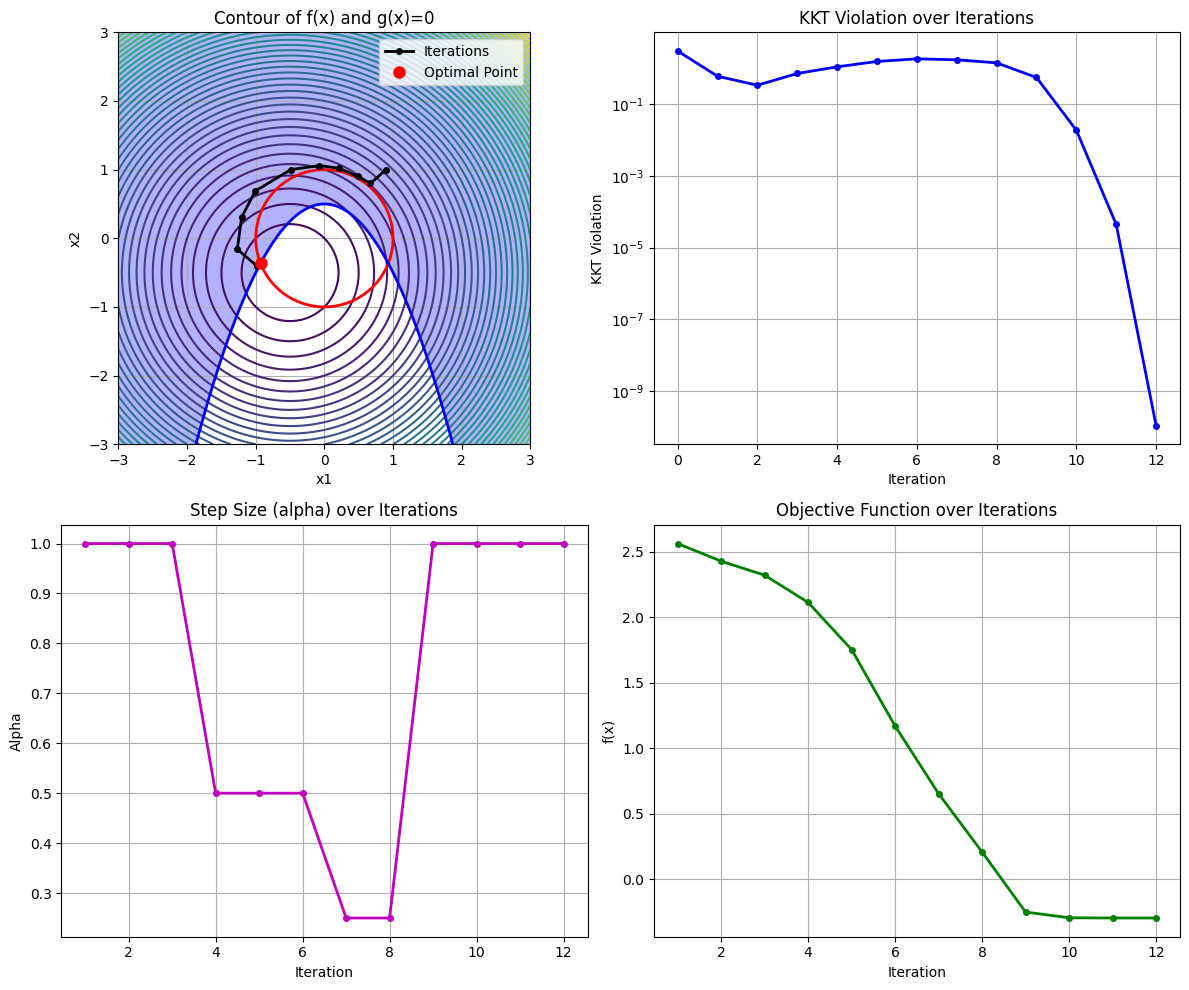

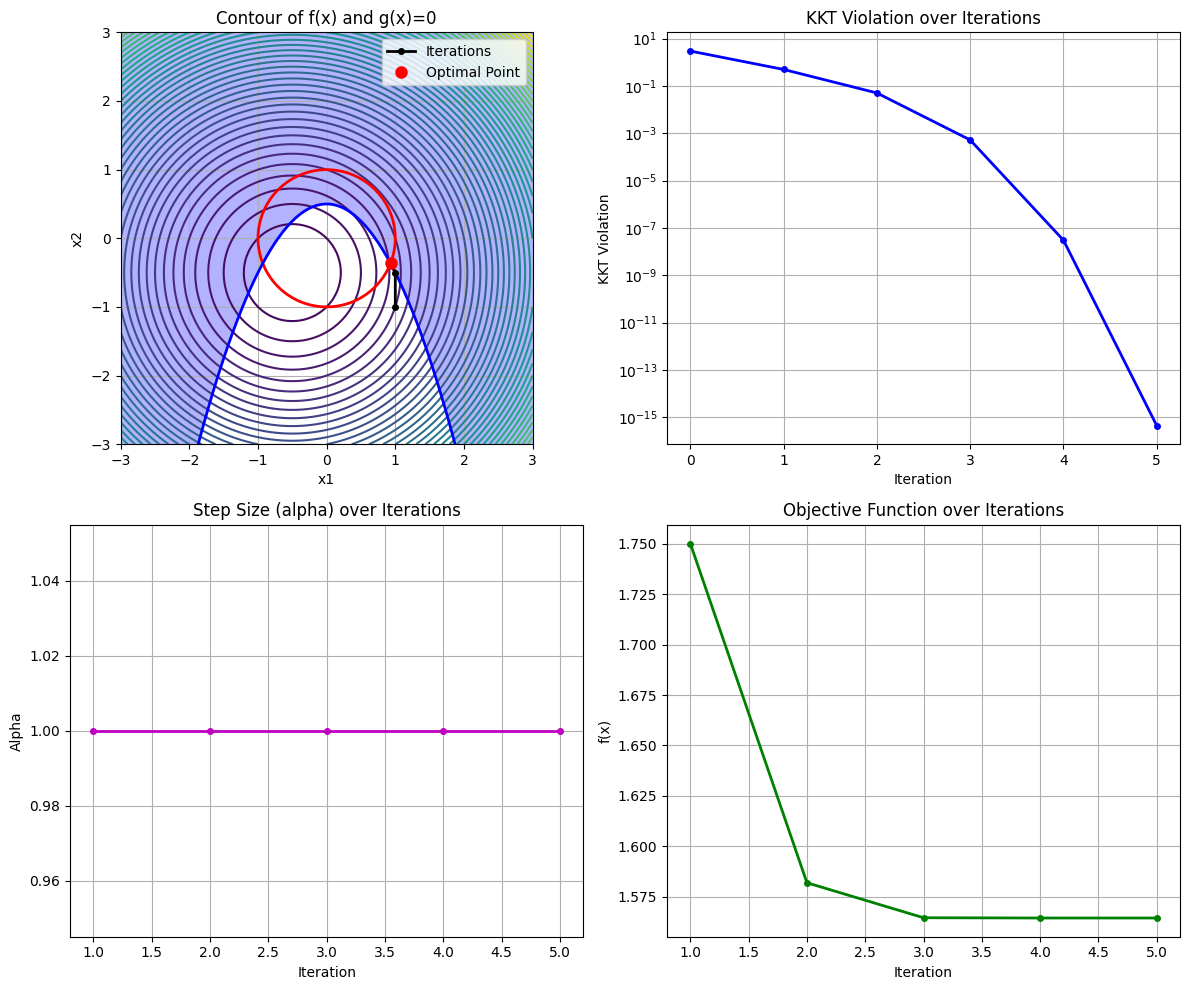

In [6]:
# 1
x_g = np.array([[0.9], [1.0]])
l_g = np.zeros_like([[0.0]])
m_g = np.zeros_like([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, m_g, post_proc = sqp(
        f, g, h, x_g, l_g, m_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-8, max_iter=400
    )
    record_result("Example 3", x_g, l_g, post_proc, x_init, m_g)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g, h)
except Exception as e:
    print("Error during optimization:", e)

# 2
x_g = np.array([[1.0], [-1.0]])
l_g = np.zeros_like([[0.0]])
m_g = np.zeros_like([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, m_g, post_proc = sqp(
        f, g, h, x_g, l_g, m_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-8, max_iter=400
    )
    record_result("Example 3", x_g, l_g, post_proc, x_init, m_g)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g, h)
except Exception as e:
    print("Error during optimization:", e)

# 3
x_g = np.array([[0.0], [-1.0]])
l_g = np.zeros_like([[0.0]])
m_g = np.zeros_like([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, m_g, post_proc = sqp(
        f, g, h, x_g, l_g, m_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-10, max_iter=400
    )
    record_result("Example 3", x_g, l_g, post_proc, x_init, m_g)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g, h)
except Exception as e:
    print("Error during optimization:", e)

**Observations.**

- $(0.9, 1)$: converges to the same $x^*$ (12 iterations), but 8 of the 12 QPs are **nonconvex** (column *QP convex*): the regularized $B$ is only positive definite on the null space of the active constraints. qpOASES solves them anyway.
- $(1, -1)$: converges to $\bar{x} = (0.9306, -0.3660)$ with $f = 1.565 > f^*$: a **local, not global, minimum**. Both constraints are active with linearly independent gradients, so $Z$ is empty and, with $\mu > 0$, SOSC holds: $\bar{x}$ is a strict local minimizer. SQP is a local method and converges to the KKT point close to the initial guess; this cannot be fixed easily (it requires a better initial guess or global optimization).
- $(0, -1)$: the **QP is infeasible** at the first iteration. With $g = 0$, $\nabla g = (0, -2)$, $h = 1.5$, $\nabla h = (0, -1)$, the linearized constraints read $-2 \Delta x_2 = 0$ and $1.5 - \Delta x_2 \le 0$: incompatible.

**Easy fix (infeasible QP):** relax the linearized constraints with slack variables penalized in the QP cost (*elastic mode*, consistent with the $\ell_1$ merit function):
$$\min_{\Delta x, s^+, s^-, t} \; \tfrac{1}{2} \Delta x^\top B \Delta x + \nabla f^\top \Delta x + \sigma \mathbf{1}^\top (s^+ + s^- + t)$$
$$\text{s.t.} \quad g + \nabla g^\top \Delta x = s^+ - s^-, \quad h + \nabla h^\top \Delta x \le t, \quad s^+, s^-, t \ge 0.$$
The relaxed QP is always feasible. **Expense:** a larger QP (extra variables), a penalty weight to tune, and steps that do not satisfy the linearized constraints, which can slow down convergence; the method can also converge to a point that only minimizes the constraint violation.

## Summary

In [7]:
print(f"{'Example':>9} | {'x0':>10} | {'solution':>18} | {'lambda':>9} | {'mu':>9} | {'iter':>4} | {'KKT':>9}")
print("-" * 86)
for r in optimization_results:
    print(
        f"{r['example']:>9} | {fmt(r['initial_guess'], 8):>10} | {fmt(r['solution']):>18} | "
        f"{fmt(r['equality_multiplier']):>9} | {fmt(r['inequality_multiplier']):>9} | "
        f"{r['iterations']:>4} | {r['kkt_violation']:>9.2e}"
    )

  Example |         x0 |           solution |    lambda |        mu | iter |       KKT
--------------------------------------------------------------------------------------
Example 3 |     [0, 1] |  [-0.9306, -0.366] | [-0.1124] |  [0.3503] |    9 |  3.03e-09
Example 3 |   [-1, -1] |  [-0.9306, -0.366] | [-0.1124] |  [0.3503] |    5 |  2.22e-16
Example 3 |   [0.9, 1] |  [-0.9306, -0.366] | [-0.1124] |  [0.3503] |   12 |  1.11e-10
Example 3 |    [1, -1] |   [0.9306, -0.366] | [-0.7329] |  [0.8044] |    5 |  4.44e-16
